# Tugas Besar 2 IF3170 — Prediksi Pembatalan Booking

**Kelompok G04 (TreeIsAllYouNeed) — algoritma: Decision Tree Learning (DTL) from scratch (C4.5)**

Notebook ini mengikuti tahapan pengolahan data pada spesifikasi tugas:
*Data Understanding → Data Cleaning → Data Transformation → Feature Selection →
Dimensionality Reduction → Modeling & Validation*, lalu menyimpan/memuat model
(poin 7 spek) dan menghasilkan file submission Kaggle.

Metrik utama: **Macro F1** (metrik evaluasi kompetisi).

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold

RANDOM_STATE = 42


def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for p in [start, *start.parents]:
        if (p / "src" / "kaggle" / "dataset" / "train.csv").exists():
            return p
    raise FileNotFoundError("jalankan notebook dari dalam repository")


REPO = find_repo_root()
DATA = REPO / "src" / "kaggle" / "dataset"
OUTPUT = REPO / "output"
OUTPUT.mkdir(exist_ok=True)
sys.path.insert(0, str(REPO / "src" / "algoritma"))

from dtl import DTL

print("repo:", REPO)

/home/majiidkun/Majiid/KULIAH/ITB/Semester5/TUBES/AI/Tubes-2/work/venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


repo: /home/majiidkun/Majiid/KULIAH/ITB/Semester5/TUBES/AI/Tubes-2/IF3170_G04_TreeIsAllYouNeed


## 1. Data Understanding

Dataset berisi catatan pemesanan penginapan dengan target biner `is_canceled`
(1 = booking dibatalkan). Fiturnya campuran numerik dan kategorikal; deskripsi
lengkap ada di halaman Data kompetisi Kaggle. Poin penting:

- **Target imbalance ~67 : 33** → semua evaluasi memakai **Macro F1** agar kedua kelas diperhitungkan.
- **`id`** adalah hash acak (ada yang terlihat seperti notasi ilmiah, mis. `123e4567`) → wajib dibaca sebagai *string* dan tidak dipakai sebagai fitur.
- 8 fitur memiliki *missing value* (3–11%) dengan proporsi yang mirip antara train dan test.
- Berdasarkan analisis sumber data (OSINT internal kelompok), dataset kompetisi adalah transformasi dari dataset publik **"Hotel Reservations"**: *missing value* disuntikkan secara artifisial (MCAR), `days_before_arrival` dan `nightly_rate_idr` diberi noise kecil, dan 64 baris duplikat ikut terbawa. Informasi ini dipakai untuk memilih strategi preprocessing di bawah — **sumber data asli tidak digunakan untuk melatih model**.

In [2]:
train = pd.read_csv(DATA / "train.csv", dtype={"id": str})
test = pd.read_csv(DATA / "test.csv", dtype={"id": str})
sample_submission = pd.read_csv(DATA / "sample_submission.csv", dtype={"id": str})

features = [c for c in train.columns if c not in ("id", "is_canceled")]
print(f"train: {train.shape}  test: {test.shape}  fitur: {len(features)}")
print(f"positive rate train: {train.is_canceled.mean():.4f}")
train.head()

train: (27373, 19)  test: (6844, 18)  fitur: 17
positive rate train: 0.3277


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


missing per fitur:


num_adults              809
num_children           3035
meal_package           1760
needs_parking          1082
room_category          1002
days_before_arrival    1123
nightly_rate_idr       2038
special_requests       2500


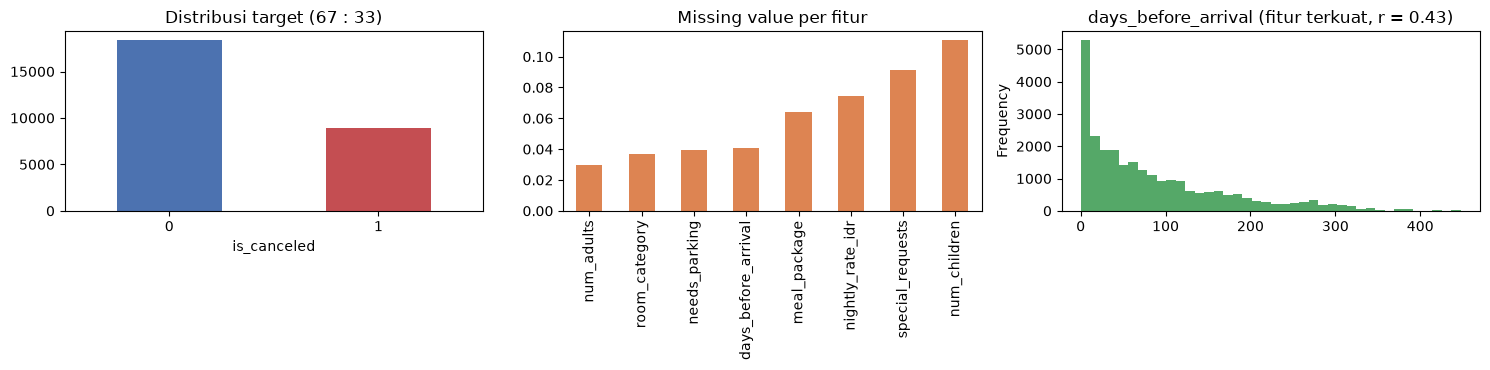

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
train.is_canceled.value_counts().sort_index().plot.bar(
    ax=axes[0], color=["#4c72b0", "#c44e52"], rot=0)
axes[0].set_title("Distribusi target (67 : 33)")
miss = train[features].isna().mean()
miss[miss > 0].sort_values().plot.bar(ax=axes[1], color="#dd8452")
axes[1].set_title("Missing value per fitur")
train.days_before_arrival.plot.hist(bins=40, ax=axes[2], color="#55a868")
axes[2].set_title("days_before_arrival (fitur terkuat, r = 0.43)")
plt.tight_layout()

print("missing per fitur:")
print(train[features].isna().sum()[lambda s: s > 0].to_string())

## 2. Data Cleaning

- **Duplikat**: 64 baris duplikat persis (fitur + label identik) dihapus. Selain itu terdeteksi **2 grup fitur-identik dengan label berbeda** — noise tak terhindarkan (fitur sama, label bertentangan) → kedua baris dipertahankan, tidak ada yang bisa dipilih tanpa informasi tambahan.
- **`id`** dibuang (identifier, bukan fitur).
- **Nilai tidak valid**: diperiksa rentang tiap fitur numerik. `num_adults = 0` (106 baris) dan `nightly_rate_idr = 0` (408 baris, biasanya tamu komplimen) adalah nilai asli dari sumber data, bukan noise → **dipertahankan**.

In [4]:
def clean(df):
    out = df.drop(columns=["id"]).drop_duplicates().reset_index(drop=True)
    return out


train_c = clean(train)
print(f"train: {len(train)} -> {len(train_c)} baris "
      f"(hapus {len(train) - len(train_c)} duplikat persis)")

feat_no_y = [c for c in train_c.columns if c != "is_canceled"]
dup = train_c[train_c.duplicated(subset=feat_no_y, keep=False)]
groups = dup.groupby(feat_no_y, dropna=False).is_canceled.nunique()
print(f"grup fitur-identik dengan label berbeda (dipertahankan): "
      f"{(groups > 1).sum()}")

num = train_c.select_dtypes(include=np.number)
print("\nrentang fitur numerik:")
print(num.agg(["min", "max"]).T.to_string())
print(f"\nnum_adults=0 : {(train_c.num_adults == 0).sum()} baris (dipertahankan)")
print(f"nightly_rate=0: {(train_c.nightly_rate_idr == 0).sum()} baris (dipertahankan)")

train: 27373 -> 27309 baris (hapus 64 duplikat persis)
grup fitur-identik dengan label berbeda (dipertahankan): 2

rentang fitur numerik:
                             min        max
num_adults                   0.0        4.0
num_children                 0.0       10.0
weekend_nights               0.0        7.0
weekday_nights               0.0       17.0
needs_parking                0.0        1.0
days_before_arrival          0.0      448.0
arrival_year              2023.0     2024.0
arrival_month                1.0       12.0
arrival_day                  1.0       31.0
is_returning_guest           0.0        1.0
prior_cancellations          0.0       13.0
prior_completed_bookings     0.0       58.0
nightly_rate_idr             0.0  9165000.0
special_requests             0.0        5.0
is_canceled                  0.0        1.0

num_adults=0 : 106 baris (dipertahankan)
nightly_rate=0: 408 baris (dipertahankan)


## 3. Data Transformation

Keputusan preprocessing disesuaikan dengan karakter data (hasil analisis sumber):

| Temuan (OSINT) | Keputusan preprocessing | Alasan |
|---|---|---|
| Missing value disuntikkan artifisial (MCAR); proporsi train ≈ test | **Imputasi median (numerik) / mode (kategorikal)**, statistik fit **hanya dari train** | MCAR → imputasi aman; mencegah kebocoran data test |
| Missing `special_requests` menaikkan rate cancel 0.408 vs 0.320 (terukur dari train) | **Missing-indicator** (`missing_<kolom>`) sebagai kandidat fitur — diuji langsung saat tuning | Sinyal nyata yang hilang jika hanya diimputasi |
| Noise ±5 hari & ±1,75% harga | tanpa perlakuan khusus | Pohon tahan noise; filter justru bisa membuang informasi |
| Fitur kategorikal bernilai string | **DTL from-scratch menerima kategorikal langsung** (split multiway) | Tidak perlu encoding untuk model utama |
| — | Encoding one-hot hanya untuk jalur sklearn & PCA; **standarisasi hanya untuk PCA** | Pohon tidak butuh normalisasi; PCA butuh fitur berskala |

*Train dan test tidak pernah digabung; semua statistik fit pada train lalu
diterapkan ke test (spek: preprocessing terpisah).*

In [5]:
CAT_STR = ["meal_package", "room_category", "booking_channel"]
TARGET = "is_canceled"


def fit_preprocessor(df, add_flags=True):
    pre = {"median": {}, "mode": {}, "flag_cols": []}
    for c in df.columns:
        if c in ("id", TARGET):
            continue
        if c in CAT_STR:
            pre["mode"][c] = df[c].mode().iloc[0]
        else:
            pre["median"][c] = df[c].median()
        if add_flags and df[c].isna().any():
            pre["flag_cols"].append(c)
    return pre


def transform(df, pre, add_flags=True):
    drop = [c for c in ("id", TARGET) if c in df.columns]
    out = df.drop(columns=drop).copy()
    for c, v in pre["median"].items():
        out[c] = pd.to_numeric(out[c], errors="coerce").fillna(v)
    for c, v in pre["mode"].items():
        out[c] = out[c].fillna(v)
    if add_flags:
        for c in pre["flag_cols"]:
            out[f"missing_{c}"] = df[c].isna().astype(float)
    return out


pre = fit_preprocessor(train_c, add_flags=False)
X_train_all = transform(train_c, pre, add_flags=False)
X_test = transform(test, pre, add_flags=False)
y_train = train_c[TARGET].to_numpy()

pre_full = fit_preprocessor(train_c, add_flags=True)
print(f"sisa missing: {int(X_train_all.isna().sum().sum())}")
print(f"kandidat missing-indicator: {pre_full['flag_cols']}")
X_train_all.head()

sisa missing: 0
kandidat missing-indicator: ['num_adults', 'num_children', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'nightly_rate_idr', 'special_requests']


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
0,2.0,0.0,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0
1,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,1644000.0,0.0
2,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0
3,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0
4,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0


### 3b. Fitur grup booking (*sibling target encoding*)

**Temuan EDA.** Sekitar **40%** booking memiliki "saudara" di train: booking lain
dengan tanggal kedatangan, lama menginap, dan kanal yang sama persis (pemesanan
rombongan). Jika `days_before_arrival` juga disamakan, label antarsaudara
konsisten **~94%**. Simpangan `days_before_arrival` di dalam grup ≈ 5 hari —
sama dengan *noise* yang disuntikkan ke data kompetisi — sehingga kecocokan
persis gagal menemukan sebagian besar grup, dan pohon biasa tidak bisa
memanfaatkan pola "booking kembar".

**Fitur.** Untuk tiap booking dicari baris *train* yang kemungkinan satu grup:
kunci keras sama (tanggal kedatangan, malam *weekend*/*weekday*, kanal — kolom
yang tidak pernah kosong), selisih lead time ≤ 10 hari, selisih harga ≤ 4%,
dan kolom lunak (kamar, paket makan, jumlah tamu, *special request*, parkir)
sama atau kosong di salah satu sisi. Fitur `sib_te` = rata-rata label saudara
yang dihaluskan (*smoothed target encoding*, Micci-Barreca 2001) dan `sib_n` =
jumlah saudara.

**Anti-kebocoran.** Untuk baris train, nilai dihitung *out-of-fold* (5 *inner
fold*), sehingga baris tidak pernah melihat labelnya sendiri dan distribusinya
sama dengan di test. Test hanya memakai label train; train dan test tidak
digabung. Di CV luar, fitur dihitung ulang di dalam tiap fold.

**Fitur tanggal booking.** `arr_ord` (tanggal kedatangan sebagai nomor hari),
`book_ord` = `arr_ord` − `days_before_arrival` (tanggal pemesanan), dan
`arr_dow` (hari kedatangan). CV 3 *seed*: +0,0023 Macro F1, naik di setiap *seed*.

In [6]:
KEY = ["arrival_year", "arrival_month", "arrival_day", "weekend_nights",
       "weekday_nights", "booking_channel"]
SOFT = ["room_category", "meal_package", "num_adults", "num_children",
        "special_requests", "needs_parking"]


def _codes(df, cols, vocab):
    out = np.empty((len(df), len(cols)))
    for j, c in enumerate(cols):
        s = df[c]
        if c in vocab:
            out[:, j] = s.map(vocab[c]).to_numpy(dtype=float)
        else:
            out[:, j] = s.to_numpy(dtype=float)
    return out


def _encode(ref, ref_y, qry, vocab, lead_tol, rate_tol, prior, m):
    rk = [tuple(r) for r in _codes(ref, KEY, vocab)]
    qk = [tuple(r) for r in _codes(qry, KEY, vocab)]
    groups: dict[tuple, list[int]] = {}
    for j, k in enumerate(rk):
        groups.setdefault(k, []).append(j)
    groups = {k: np.asarray(v) for k, v in groups.items()}
    rl = ref["days_before_arrival"].to_numpy(dtype=float)
    ql = qry["days_before_arrival"].to_numpy(dtype=float)
    rr = ref["nightly_rate_idr"].to_numpy(dtype=float)
    qr = qry["nightly_rate_idr"].to_numpy(dtype=float)
    rs = _codes(ref, SOFT, vocab)
    qs = _codes(qry, SOFT, vocab)
    n = np.zeros(len(qry))
    s = np.zeros(len(qry))
    for i, k in enumerate(qk):
        idx = groups.get(k)
        if idx is None:
            continue
        ok = np.ones(len(idx), dtype=bool)
        if not np.isnan(ql[i]):
            ok &= np.isnan(rl[idx]) | (np.abs(rl[idx] - ql[i]) <= lead_tol)
        if not np.isnan(qr[i]):
            ok &= np.isnan(rr[idx]) | (np.abs(rr[idx] - qr[i])
                                       <= rate_tol * max(qr[i], 1.0))
        soft = rs[idx]
        ok &= np.all(np.isnan(soft) | np.isnan(qs[i]) | (soft == qs[i]), axis=1)
        sel = idx[ok]
        n[i] = len(sel)
        s[i] = ref_y[sel].sum()
    return (s + m * prior) / (n + m), n


# Sumber: D. Micci-Barreca, SIGKDD Explorations 3(1), 2001 (smoothed target encoding).
def sibling_features(X_train, y_train, X_other=None, lead_tol=10,
                     rate_tol=0.04, m=1.0, inner=5, seed=0):
    X_train = X_train.reset_index(drop=True)
    y_train = np.asarray(y_train, dtype=float)
    prior = float(y_train.mean())
    vocab = {c: {v: float(i) for i, v in
                 enumerate(sorted(X_train[c].dropna().unique()))}
             for c in KEY + SOFT if X_train[c].dtype.kind not in "biuf"}
    folds = np.array_split(np.random.default_rng(seed).permutation(len(X_train)),
                           inner)
    te_tr = np.zeros(len(X_train))
    n_tr = np.zeros(len(X_train))
    for b in folds:
        a = np.setdiff1d(np.arange(len(X_train)), b)
        te_tr[b], n_tr[b] = _encode(X_train.iloc[a], y_train[a],
                                    X_train.iloc[b], vocab, lead_tol,
                                    rate_tol, prior, m)
    train_feats = pd.DataFrame({"sib_te": te_tr, "sib_n": n_tr})
    if X_other is None:
        return train_feats, None
    t, n = _encode(X_train, y_train, X_other.reset_index(drop=True), vocab,
                   lead_tol, rate_tol, prior, m)
    return train_feats, pd.DataFrame({"sib_te": t,
                                      "sib_n": n * (inner - 1) / inner})


def booking_date_features(df):
    dt = pd.to_datetime(dict(year=df.arrival_year, month=df.arrival_month,
                             day=df.arrival_day))
    arr = (dt - pd.Timestamp("2023-01-01")).dt.days.astype(float)
    return pd.DataFrame({"arr_ord": arr,
                         "book_ord": arr - df["days_before_arrival"],
                         "arr_dow": dt.dt.day_of_week.astype(float)},
                        index=df.index)


def build_features(train_df, other_df, params):
    flags = params["missing_flags"]
    raw_train, raw_other = train_df, other_df
    if params.get("book_date", False):
        train_df = pd.concat([train_df, booking_date_features(train_df)], axis=1)
        other_df = pd.concat([other_df, booking_date_features(other_df)], axis=1)
    pre_b = fit_preprocessor(train_df, add_flags=flags)
    A = transform(train_df, pre_b, add_flags=flags).reset_index(drop=True)
    B = transform(other_df, pre_b, add_flags=flags).reset_index(drop=True)
    if params.get("sibling", False):
        raw_tr = raw_train.drop(columns=[TARGET])
        raw_ot = raw_other.drop(columns=[c for c in ("id", TARGET) if c in raw_other])
        f_tr, f_ot = sibling_features(raw_tr, raw_train[TARGET], raw_ot)
        A = pd.concat([A, f_tr], axis=1)
        B = pd.concat([B, f_ot], axis=1)
    return A, B


_sib_tr, _sib_te = sibling_features(train_c.drop(columns=[TARGET]), y_train,
                                    test.drop(columns=["id"]))
print(f"baris dengan >=1 saudara: train (OOF) {(_sib_tr.sib_n > 0).mean():.3f}"
      f" | test {(_sib_te.sib_n > 0).mean():.3f}")
print(_sib_tr.assign(y=y_train).groupby(pd.cut(_sib_tr.sib_te, [0, .2, .4, .6, .8, 1]),
                                        observed=True).y.agg(["mean", "size"]))

baris dengan >=1 saudara: train (OOF) 0.379 | test 0.405
                mean   size
sib_te                     
(0.0, 0.2]  0.039485   5901
(0.2, 0.4]  0.282221  17178
(0.4, 0.6]  0.466102    236
(0.6, 0.8]  0.851299   1540
(0.8, 1.0]  0.995110   2454


## 4. Feature Selection

Skor tiap fitur dihitung dengan **Cramér's V** (kategorikal) dan
**korelasi point-biserial** |r| (numerik) terhadap target, lalu divalidasi
dengan CV: apakah membuang fitur ber-skor rendah meningkatkan Macro F1?
(Catatan: peringkat dihitung pada seluruh train — bersifat indikatif; keputusan
berdasar skor CV.)

In [7]:
from scipy import stats as sps


def feature_scores(X, y):
    scores = {}
    for c in X.columns:
        if c in CAT_STR:
            ct = pd.crosstab(X[c].astype(str), y).values
            chi2 = sps.chi2_contingency(ct)[0]
            n, r_, k_ = ct.sum(), ct.shape[0], ct.shape[1]
            scores[c] = float(np.sqrt(chi2 / (n * (min(r_, k_) - 1))))
        else:
            scores[c] = float(abs(sps.pearsonr(X[c].fillna(X[c].median()), y)[0]))
    return pd.Series(scores).sort_values(ascending=False)


rank = feature_scores(X_train_all, y_train)
print(rank.to_string())

days_before_arrival         0.430930
special_requests            0.250820
arrival_year                0.179515
booking_channel             0.146545
nightly_rate_idr            0.129245
is_returning_guest          0.107211
weekday_nights              0.097503
num_adults                  0.087399
meal_package                0.085972
needs_parking               0.083612
weekend_nights              0.060334
prior_completed_bookings    0.058929
room_category               0.041303
prior_cancellations         0.035032
num_children                0.029058
arrival_day                 0.019630
arrival_month               0.016124


In [8]:
def cv_macro_f1(X, y, factory, n_splits=5, state=RANDOM_STATE):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=state)
    scores = []
    for tr, va in skf.split(X, y):
        m = factory()
        m.fit(X.iloc[tr], y[tr])
        scores.append(f1_score(y[va], m.predict(X.iloc[va]), average="macro"))
    return float(np.mean(scores)), float(np.std(scores))


def dtl_factory(**kw):
    base = dict(max_depth=12, min_samples_leaf=5)
    base.update(kw)
    return lambda: DTL(**base)


sel_results = {"semua fitur": cv_macro_f1(X_train_all, y_train, dtl_factory())}
for k in (14, 10):
    cols = list(rank.head(k).index)
    sel_results[f"top-{k}"] = cv_macro_f1(X_train_all[cols], y_train,
                                          dtl_factory())
for name, (m, s) in sel_results.items():
    print(f"{name:12s} MacroF1 = {m:.4f} +/- {s:.4f}")

semua fitur  MacroF1 = 0.8300 +/- 0.0052
top-14       MacroF1 = 0.8153 +/- 0.0051
top-10       MacroF1 = 0.8147 +/- 0.0029


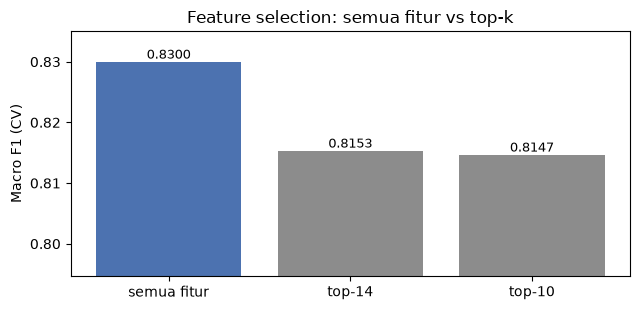

In [9]:
plt.figure(figsize=(6.5, 3.2))
names = list(sel_results)
vals = [sel_results[n][0] for n in names]
plt.bar(names, vals, color=["#4c72b0" if n == "semua fitur" else "#8c8c8c"
                            for n in names])
plt.ylim(min(vals) - 0.02, max(vals) + 0.005)
plt.ylabel("Macro F1 (CV)")
plt.title("Feature selection: semua fitur vs top-k")
for i, v in enumerate(vals):
    plt.text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()

## 5. Dimensionality Reduction (PCA)

Spek menyebut PCA *jika jumlah fitur besar*. Dengan 17 fitur (+ indikator)
jumlahnya tidak besar, tetapi PCA tetap diuji: fitur dikodekan one-hot,
distandarisasi, lalu PCA mempertahankan 95% varians. Divalidasi dengan CV —
keputusan tetap berdasar skor, bukan asumsi.

PCA menyimpan 24 komponen dari 30 fitur untuk 95% varians


DTL + PCA    : MacroF1 = 0.7796 +/- 0.0034
DTL tanpa PCA: MacroF1 = 0.8300 +/- 0.0052


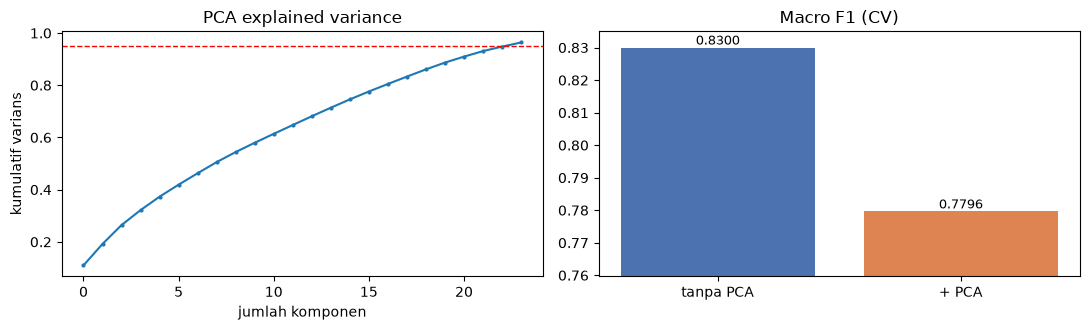

In [10]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_sk_all = pd.get_dummies(X_train_all, columns=CAT_STR, dtype=float)
scaler = StandardScaler().fit(X_sk_all)
Z = scaler.transform(X_sk_all)
pca = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(Z)
X_pca = pd.DataFrame(pca.transform(Z), index=X_train_all.index)

print(f"PCA menyimpan {pca.n_components_} komponen dari {Z.shape[1]} fitur "
      f"untuk 95% varians")
res_pca = cv_macro_f1(X_pca, y_train, dtl_factory())
res_raw = sel_results["semua fitur"]
print(f"DTL + PCA    : MacroF1 = {res_pca[0]:.4f} +/- {res_pca[1]:.4f}")
print(f"DTL tanpa PCA: MacroF1 = {res_raw[0]:.4f} +/- {res_raw[1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(np.cumsum(pca.explained_variance_ratio_), marker=".", ms=4)
axes[0].axhline(0.95, ls="--", c="r", lw=1)
axes[0].set_xlabel("jumlah komponen")
axes[0].set_ylabel("kumulatif varians")
axes[0].set_title("PCA explained variance")
labels = ["tanpa PCA", "+ PCA"]
vals = [res_raw[0], res_pca[0]]
axes[1].bar(labels, vals, color=["#4c72b0", "#dd8452"])
axes[1].set_ylim(min(vals) - 0.02, max(vals) + 0.005)
axes[1].set_title("Macro F1 (CV)")
for i, v in enumerate(vals):
    axes[1].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()

## 6. Modeling dan Validation — DTL from scratch

Model: **class `DTL` (C4.5)** di `src/algoritma/dtl/`, diimplementasikan dari
scratch dengan NumPy mengikuti materi kuliah:

- *entropy* & *information gain* (Materi 10a), **gain ratio** dengan heuristik
  gain di atas rata-rata (Materi 10c hlm. 27) sebagai kriteria pemilihan fitur;
- *midpoint threshold* untuk fitur kontinu (Materi 10c hlm. 18–19);
- **missing value**: distribusi fraksional ke tiap anak saat training
  (Materi 10c hlm. 22) + indikator missing dari preprocessing;
- stop rules: pure node, `min_samples_leaf`, `max_depth` (Materi 10a hlm. 14);
- pruning opsional: *reduced error* (Materi 10c hlm. 11) dan *cost-complexity*
  (Breiman et al. 1984 — di luar materi kelas, dicantumkan sebagai referensi).

Validasi: **5-fold stratified CV**, seed tetap, metrik Macro F1.
Perbandingan pustaka memakai `DecisionTreeClassifier` dengan pemetaan parameter
spek untuk C4.5: `criterion='entropy'` + `ccp_alpha`.

DTL from-scratch (C4.5):
  Macro F1  = 0.8300 +/- 0.0052
  Accuracy  = 0.8517
  Precision = 0.7844
  Recall    = 0.7547


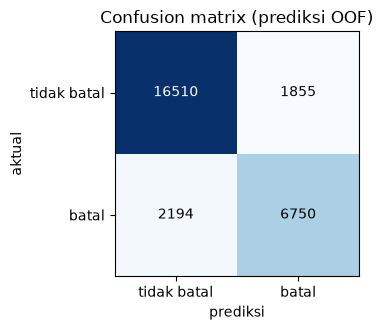

In [11]:
def cv_oof(X, y, factory, n_splits=5, state=RANDOM_STATE):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=state)
    scores, oof = [], np.zeros(len(y), dtype=int)
    for tr, va in skf.split(X, y):
        m = factory()
        m.fit(X.iloc[tr], y[tr])
        pred = m.predict(X.iloc[va])
        oof[va] = pred
        scores.append(f1_score(y[va], pred, average="macro"))
    return np.asarray(scores), oof


scores_dtl, oof_dtl = cv_oof(X_train_all, y_train, dtl_factory())
print(f"DTL from-scratch (C4.5):")
print(f"  Macro F1  = {scores_dtl.mean():.4f} +/- {scores_dtl.std():.4f}")
print(f"  Accuracy  = {accuracy_score(y_train, oof_dtl):.4f}")
print(f"  Precision = {precision_score(y_train, oof_dtl):.4f}")
print(f"  Recall    = {recall_score(y_train, oof_dtl):.4f}")

cm = confusion_matrix(y_train, oof_dtl)
plt.figure(figsize=(4, 3.4))
plt.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, str(v), ha="center", va="center",
             color="white" if v > cm.max() / 2 else "black")
plt.xticks([0, 1], ["tidak batal", "batal"])
plt.yticks([0, 1], ["tidak batal", "batal"])
plt.xlabel("prediksi")
plt.ylabel("aktual")
plt.title("Confusion matrix (prediksi OOF)")
plt.tight_layout()

model                                    Macro F1 (CV)
------------------------------------------------------------
DTL from-scratch (C4.5)                  0.8300 +/- 0.0052
entropy (pemetaan ID3/C4.5 spek)         0.8285 +/- 0.0042
entropy + ccp_alpha (C4.5 spek)          0.8144 +/- 0.0039
gini (pemetaan CART spek)                0.8312 +/- 0.0047


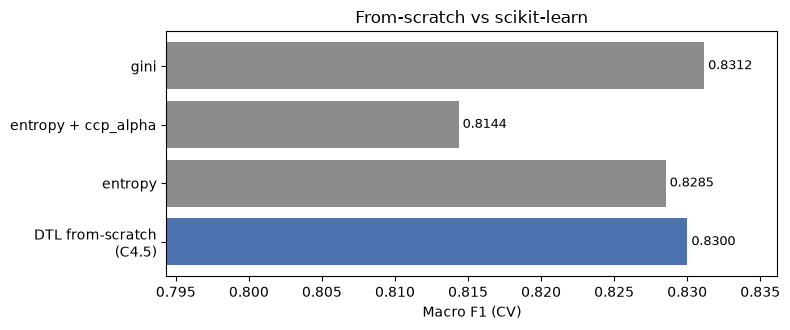

In [12]:
from sklearn.tree import DecisionTreeClassifier

sklearn_configs = {
    "entropy (pemetaan ID3/C4.5 spek)": dict(criterion="entropy"),
    "entropy + ccp_alpha (C4.5 spek)": dict(criterion="entropy", ccp_alpha=0.001),
    "gini (pemetaan CART spek)": dict(criterion="gini"),
}
sk_results = {}
for name, kw in sklearn_configs.items():
    def factory(kw=kw):
        return DecisionTreeClassifier(random_state=RANDOM_STATE,
                                      max_depth=12, min_samples_leaf=5, **kw)
    sk_results[name] = cv_macro_f1(X_sk_all, y_train, factory)

print(f"{'model':40s} Macro F1 (CV)")
print("-" * 60)
print(f"{'DTL from-scratch (C4.5)':40s} {res_raw[0]:.4f} +/- {res_raw[1]:.4f}")
for name, (m, s) in sk_results.items():
    print(f"{name:40s} {m:.4f} +/- {s:.4f}")

plt.figure(figsize=(8, 3.4))
labels = ["DTL from-scratch\n(C4.5)"] + [n.split(" (")[0] for n in sk_results]
vals = [res_raw[0]] + [v[0] for v in sk_results.values()]
colors = ["#4c72b0"] + ["#8c8c8c"] * len(sk_results)
plt.barh(labels, vals, color=colors)
plt.xlim(min(vals) - 0.02, max(vals) + 0.005)
plt.xlabel("Macro F1 (CV)")
plt.title("From-scratch vs scikit-learn")
for i, v in enumerate(vals):
    plt.text(v, i, f" {v:.4f}", va="center", fontsize=9)
plt.tight_layout()

## 7. Tuning hyperparameter (5-fold CV pada train)

Semua keputusan (fitur, hyperparameter, threshold) dipilih dengan **5-fold
stratified CV pada train**, memakai pipeline `build_features` yang dihitung
ulang di dalam tiap fold. Label test tidak dipakai sama sekali.

Catatan implementasi: `cost_complexity_prune` pada `DTL` menghitung error
dalam **jumlah baris** (bukan proporsi seperti `ccp_alpha` sklearn), sehingga
`ccp_alpha=2.5` berarti "pangkas subtree yang mengurangi error < 2,5 baris
per daun tambahan" (setara ≈ 1e-4 dalam satuan sklearn untuk ~22 ribu baris).

Metode pruning yang dibandingkan: tanpa pruning, *reduced-error pruning*
(Materi 10c), *pessimistic/error-based pruning* C4.5 (Quinlan 1993, CF),
dan *cost-complexity pruning* (Breiman et al. 1984). Grid hyperparameter
lengkap (kedalaman, daun minimum, α, CF, bobot kelas, MDL penalty, kriteria
split, ablation fitur) dijalankan di luar notebook dengan 3 *seed* CV;
ringkasannya ada di laporan.

Hasil tuning di-*hardcode* sebagai `FINAL_PARAMS` agar notebook reproducible;
sel CV di bawah memverifikasi bahwa konfigurasi itu memang terbaik.

**Hasil CV 3 *seed* (42, 1, 7; Macro F1 rata-rata @ threshold 0,4)** — dasar
pemilihan `FINAL_PARAMS`:

| Konfigurasi (semua: sibling + tanggal booking) | Rata-rata | Seed 42 / 1 / 7 |
|---|---|---|
| cost-complexity α=2,5, depth 20, leaf 2 (**FINAL**) | **0,8661** | 0,8673 / 0,8656 / 0,8654 |
| pessimistic C4.5 CF=0,03, leaf 1 | 0,8658 | 0,8676 / 0,8650 / 0,8649 |
| pessimistic C4.5 CF=0,02, leaf 2 | 0,8657 | 0,8674 / 0,8650 / 0,8647 |
| cost-complexity α=2, depth 30, leaf 2 | 0,8646 | 0,8668 / 0,8642 / 0,8628 |
| reduced-error (val 30%) *(1 seed)* | 0,8641 | 0,8641 / – / – |
| tanpa pruning, depth 30 *(1 seed)* | 0,8343 | 0,8343 / – / – |

Dataran α 2,5–2,75 × depth 16–20 semuanya 0,8659–0,8663; dipilih titik
tengahnya. Varian yang tidak membantu: `class_weight` (balanced −0,016),
MDL penalty, kriteria *information gain* murni, fitur lama menginap/harga
per tamu/ADR-Q3, penggabungan kategori langka, dan membuang fitur apa pun.

In [13]:
FINAL_PARAMS = {"missing_flags": True, "sibling": True, "book_date": True,
                "max_depth": 20, "min_samples_leaf": 2,
                "pruning": "cost_complexity", "ccp_alpha": 2.5,
                "threshold": 0.4}

In [14]:
def macro_f1(y, pred):
    return f1_score(y, pred, average="macro")


def make_dtl(params):
    return DTL(max_depth=params["max_depth"],
               min_samples_leaf=params["min_samples_leaf"],
               pruning=params["pruning"], ccp_alpha=params["ccp_alpha"],
               confidence=params.get("confidence", 0.25))


def cv_pipeline_proba(params, n_splits=5, state=RANDOM_STATE):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=state)
    proba = np.zeros(len(y_train))
    for tr_i, va_i in skf.split(train_c, y_train):
        A, B = build_features(train_c.iloc[tr_i], train_c.iloc[va_i], params)
        m = make_dtl(params)
        proba[va_i] = m.fit(A, y_train[tr_i]).predict_proba(B)[:, 1]
    return proba


base = dict(missing_flags=True, sibling=True, book_date=True, max_depth=20,
            min_samples_leaf=2, pruning="cost_complexity", ccp_alpha=2.5)
candidates = {
    "tanpa sibling & tgl booking (pipeline lama)": dict(
        base, sibling=False, book_date=False, ccp_alpha=0.001),
    "tanpa pruning (d30)": dict(base, max_depth=30, pruning="none"),
    "reduced-error pruning (val 30%)": dict(base, max_depth=None,
                                            pruning="reduced_error"),
    "pessimistic C4.5 (CF=0.03, leaf 1)": dict(base, min_samples_leaf=1,
                                              pruning="pessimistic",
                                              confidence=0.03),
    "cost-complexity a=2 (d30)": dict(base, max_depth=30, ccp_alpha=2.0),
    "cost-complexity a=2.5 (d20) (FINAL)": dict(base),
}
cv_proba = {}
rows = []
for name, p in candidates.items():
    cv_proba[name] = cv_pipeline_proba(p)
    rows.append((name, macro_f1(y_train, (cv_proba[name] >= 0.5).astype(int)),
                 macro_f1(y_train, (cv_proba[name] >= FINAL_PARAMS["threshold"]).astype(int))))
tuning = pd.DataFrame(rows, columns=["konfigurasi", "MacroF1@0.5",
                                     f"MacroF1@{FINAL_PARAMS['threshold']}"])
print(tuning.to_string(index=False))
oof_final = cv_proba["cost-complexity a=2.5 (d20) (FINAL)"]

                                konfigurasi  MacroF1@0.5  MacroF1@0.4
tanpa sibling & tgl booking (pipeline lama)     0.831785     0.831263
                        tanpa pruning (d30)     0.834011     0.834280
            reduced-error pruning (val 30%)     0.863942     0.864097
         pessimistic C4.5 (CF=0.03, leaf 1)     0.867536     0.867317
                  cost-complexity a=2 (d30)     0.866288     0.866818
        cost-complexity a=2.5 (d20) (FINAL)     0.867324     0.867300


In [15]:
col = tuning.columns[2]
best_row = tuning.sort_values(col, ascending=False).iloc[0]
final_score = tuning.loc[tuning.konfigurasi.str.endswith("(FINAL)"), col].item()
print(f"terbaik pada seed notebook : {best_row.konfigurasi} ({best_row[col]:.4f})")
print(f"FINAL                      : {final_score:.4f}")
assert final_score >= best_row[col] - 0.002, "FINAL tertinggal jauh dari kandidat terbaik"

terbaik pada seed notebook : pessimistic C4.5 (CF=0.03, leaf 1) (0.8673)
FINAL                      : 0.8673


## 8. Cost-sensitive classification (bonus spek #7)

False Positive (prediksi batal, aktual tidak) dinilai **2× lebih mahal** daripada
False Negative karena penginapan bisa *overbooked*. Dengan biaya `FP = 2` dan
`FN = 1`, aturan keputusan bayes yang meminimalkan biaya ekspektasi adalah
memprediksi **batal jika P(batal | x) > 2/3** (mengganti threshold 1/2).

Analisis di bawah membandingkan dampak aturan tersebut terhadap Macro F1
menggunakan prediksi *out-of-fold*.

In [16]:
def cv_oof_proba(X, y, factory, n_splits=5, state=RANDOM_STATE):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=state)
    proba = np.zeros(len(y))
    for tr, va in skf.split(X, y):
        m = factory()
        m.fit(X.iloc[tr], y[tr])
        proba[va] = m.predict_proba(X.iloc[va])[:, 1]
    return proba


oof_proba = cv_oof_proba(X_train_all, y_train, dtl_factory())
f1_default = f1_score(y_train, (oof_proba >= 0.5).astype(int), average="macro")
f1_cost = f1_score(y_train, (oof_proba >= 2 / 3).astype(int), average="macro")
grid_t = np.round(np.arange(0.30, 0.71, 0.05), 2)
f1_best_t = max(f1_score(y_train, (oof_proba >= t).astype(int), average="macro")
                for t in grid_t)
best_t = max(grid_t, key=lambda t: f1_score(y_train,
              (oof_proba >= t).astype(int), average="macro"))

print(f"threshold 0.50 (default) : Macro F1 = {f1_default:.4f}")
print(f"threshold 2/3 (cost-sensitive): Macro F1 = {f1_cost:.4f}")
print(f"threshold F1-optimal ({best_t:.2f})  : Macro F1 = {f1_best_t:.4f}")
if f1_cost >= f1_default:
    print("-> aturan cost-sensitive TIDAK menurunkan Macro F1")
else:
    print(f"-> aturan cost-sensitive menurunkan Macro F1 "
          f"({f1_default - f1_cost:+.4f}); biaya FP tetap dianalisis di laporan, "
          f"sedangkan threshold submission dipilih berdasar Macro F1")

threshold 0.50 (default) : Macro F1 = 0.8298
threshold 2/3 (cost-sensitive): Macro F1 = 0.8138
threshold F1-optimal (0.50)  : Macro F1 = 0.8298
-> aturan cost-sensitive menurunkan Macro F1 (+0.0161); biaya FP tetap dianalisis di laporan, sedangkan threshold submission dipilih berdasar Macro F1


### Pemilihan threshold (OOF train)

Ambang keputusan `P(batal) ≥ t` dipilih dari kurva Macro F1 prediksi
*out-of-fold* konfigurasi final. Kurvanya landai di sekitar optimum, jadi
dipilih nilai yang stabil di beberapa *seed* CV, bukan puncak tunggal.

threshold 0.50          : OOF Macro F1 0.8673
threshold FINAL 0.40    : OOF Macro F1 0.8673
puncak kurva 0.46       : OOF Macro F1 0.8675


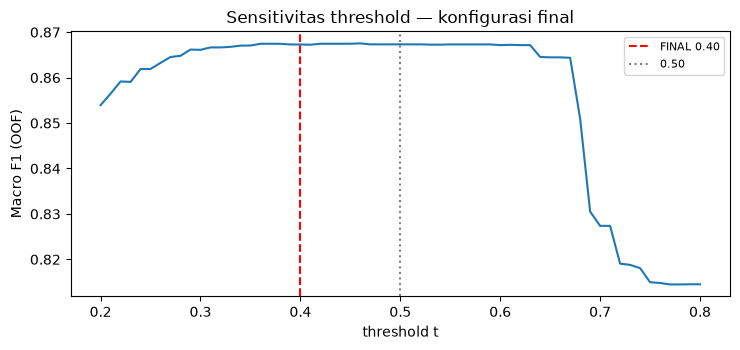

In [17]:
ts = np.round(np.arange(0.20, 0.801, 0.01), 2)
curve = [macro_f1(y_train, (oof_final >= t).astype(int)) for t in ts]
i_best = int(np.argmax(curve))
print(f"threshold 0.50          : OOF Macro F1 {macro_f1(y_train, (oof_final >= 0.5).astype(int)):.4f}")
print(f"threshold FINAL {FINAL_PARAMS['threshold']:.2f}    : OOF Macro F1 "
      f"{macro_f1(y_train, (oof_final >= FINAL_PARAMS['threshold']).astype(int)):.4f}")
print(f"puncak kurva {ts[i_best]:.2f}       : OOF Macro F1 {curve[i_best]:.4f}")

plt.figure(figsize=(7.5, 3.6))
plt.plot(ts, curve)
plt.axvline(FINAL_PARAMS["threshold"], c="r", ls="--",
            label=f"FINAL {FINAL_PARAMS['threshold']:.2f}")
plt.axvline(0.5, c="gray", ls=":", label="0.50")
plt.xlabel("threshold t")
plt.ylabel("Macro F1 (OOF)")
plt.title("Sensitivitas threshold — konfigurasi final")
plt.legend(fontsize=8)
plt.tight_layout()

## 9. Final model dan submission Kaggle

Model final dilatih pada **seluruh data train** (setelah cleaning +
preprocessing yang sama) dengan `FINAL_PARAMS`, memprediksi `test.csv`, dan
menulis `output/submission.csv` dengan format persis `sample_submission.csv`.
Model disimpan ke `output/dtl_model.json` (poin spek 7) dan dimuat ulang untuk
memastikan prediksinya identik.

In [18]:
params = FINAL_PARAMS
X_tr_final, X_te_final = build_features(train_c, test, params)

final_model = make_dtl(params).fit(X_tr_final, y_train)

proba = final_model.predict_proba(X_te_final)[:, 1]
pred = (proba >= params["threshold"]).astype(int)

submission = pd.DataFrame({"id": test["id"], "is_canceled": pred})
submission.to_csv(OUTPUT / "submission.csv", index=False)

sub = pd.read_csv(OUTPUT / "submission.csv", dtype={"id": str})
assert list(sub.columns) == list(sample_submission.columns), "header salah"
assert len(sub) == len(test) == len(sample_submission), "jumlah baris salah"
assert sub["id"].tolist() == test["id"].tolist(), "urutan id berbeda"
assert set(sub["is_canceled"].unique()) <= {0, 1}, "label bukan 0/1"

model_path = OUTPUT / "dtl_model.json"
final_model.save(model_path)
reloaded = DTL.load(model_path)
np.testing.assert_array_equal(final_model.predict(X_te_final),
                              reloaded.predict(X_te_final))

print("format submission valid; model save/load identik")
print(f"prediksi positif: {pred.mean():.4f} (train positive rate "
      f"{y_train.mean():.4f})")
print("params:", params)
sub.head()

format submission valid; model save/load identik
prediksi positif: 0.2976 (train positive rate 0.3275)
params: {'missing_flags': True, 'sibling': True, 'book_date': True, 'max_depth': 20, 'min_samples_leaf': 2, 'pruning': 'cost_complexity', 'ccp_alpha': 2.5, 'threshold': 0.4}


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


## Ringkasan

- **Pipeline**: cleaning (dedup 64 baris) → imputasi median/mode + missing-indicator (fit di train) → feature selection (diuji, tidak menang) → PCA (diuji, tidak menang) → fitur tanggal booking + fitur grup booking (*sibling target encoding*, OOF) → modeling.
- **Model**: DTL from-scratch (C4.5) — kelas `DTL` di `src/algoritma/dtl/`, hanya NumPy; perbandingan dengan `DecisionTreeClassifier` sesuai pemetaan parameter spek.
- **Validasi**: 5-fold stratified CV, Macro F1, seed tetap → notebook reproducible.
- **Submission**: `output/submission.csv` (format `sample_submission.csv`), model tersimpan di `output/dtl_model.json`.
- Semua tuning memakai CV pada train; label test tidak dipakai.

### Referensi

1. Spesifikasi Tugas Besar 2 IF3170 2026/2027.
2. N. U. Maulidevi, *Decision Tree* (Materi 10a) & *Issues in Decision Tree* (Materi 10c), IF3170, 2026.
3. L. Breiman, J. Friedman, R. Olshen, C. Stone, *Classification and Regression Trees*, 1984 (cost-complexity pruning).
4. J. R. Quinlan, *C4.5: Programs for Machine Learning*, Morgan Kaufmann, 1993 (pessimistic/error-based pruning, `AddErrs`).
4b. J. R. Quinlan, "Improved use of continuous attributes in C4.5," *Journal of Artificial Intelligence Research* 4:77–90, 1996 (MDL penalty).
4c. scikit-learn: `DecisionTreeClassifier` — https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
5. D. Micci-Barreca, *A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems*, SIGKDD Explorations 3(1), 2001.
6. N. Antonio, A. de Almeida, L. Nunes, *An automated machine learning based decision support system to predict hotel booking cancellations*, Data Science Journal 18(1):32, 2019.
7. Kaggle competition — Hotel Booking Cancellation Prediction.